# ML06: Explain the model with SHAP (Task 8)
**Goal:** find out **which precursors** the model uses, and check that this is physically sensible.

SHAP splits each prediction into contributions from each feature (in log-odds). Averaged over all days, it ranks the precursors;
for one day (for example the E1 peak), it shows why the model gave a high probability on that day.

At the end, this notebook writes `results/summary_for_email.txt`: the numbers for your reply to Dr Vergopolan.

In [1]:
!pip install -q shap

In [2]:
import os, glob, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

BASE = os.environ.get('PML_BASE', '/content/drive/MyDrive/PrecursorML')   # this project
EPE  = os.environ.get('PML_EPE',  '/content/drive/MyDrive/EPE2025')       # flood paper: shapefiles + shared IMD files
DATA, RES = f'{BASE}/data', f'{BASE}/results'
for d in (DATA, RES): os.makedirs(d, exist_ok=True)

TARGET      = 'ChenabRavi'                   # basin whose extreme rain days we predict
PCT         = 95                             # extreme day = IMD basin rain >= 95th percentile of JJAS days
YEARS       = list(range(1979, 2026))
TRAIN_YEARS = list(range(1979, 2025))        # 2025 is kept aside as an independent test
EPISODES    = {'E1': ('2025-08-23', '2025-08-26'), 'E2': ('2025-08-29', '2025-09-03')}   # START-date labels

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

table = pd.read_csv(f'{DATA}/features_{TARGET}.csv', index_col=0, parse_dates=True)
y, yr = table['extreme'], table.index.year
ATMOS = [c_ for c_ in table if '_lag' in c_ and c_ != 'rain_lag1'] + ['doy_sin', 'doy_cos']
LAG1  = [c_ for c_ in ATMOS if c_.endswith('_lag1')] + ['doy_sin', 'doy_cos']
train = yr <= 2024
BLOCKS = np.array_split(TRAIN_YEARS, 5)        # 5 blocks of ~9 consecutive years: train on 4, test on 1
print(len(ATMOS), 'atmospheric features |', int(y[train].sum()), 'extreme days in', int(train.sum()), 'training days')

def cv_predict(make_model, cols):
    """Out-of-fold probabilities for 1979-2024: each block is predicted by a model that never saw those years."""
    p = pd.Series(np.nan, index=table.index[train])
    for blk in BLOCKS:
        te = np.isin(yr[train], blk); tr_ = ~te
        if te.sum() == 0: continue                 # block with no data yet (years still downloading)
        m = make_model().fit(table.loc[train, cols][tr_], y[train][tr_])
        p[te] = m.predict_proba(table.loc[train, cols][te])[:, 1]
    return p

def scores(p, name):
    yt = y[train]; base = yt.mean()
    k = max(1, int(round(0.05 * len(p))))                    # the 5% of days with the highest probability
    top = p.sort_values(ascending=False).index[:k]
    return dict(model=name,
                ROC_AUC=round(roc_auc_score(yt, p), 3),
                PR_AUC=round(average_precision_score(yt, p), 3), base_rate=round(base, 3),
                BSS=round(1 - brier_score_loss(yt, p) / brier_score_loss(yt, np.full(len(p), base)), 3),
                hit_rate_top5pct=round(yt.loc[top].mean(), 3),
                extremes_caught_top5pct=round(yt.loc[top].sum() / yt.sum(), 3))

def logreg(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))

def plot_2025(models, fname, title):
    """Fit each model on 1979-2024 and plot its 2025 probabilities with the IMD rain."""
    t25 = table[(yr == 2025)].loc['2025-07-15':'2025-09-20']
    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    ax2 = ax.twinx()
    ax2.bar(t25.index, t25['rain'], color='grey', alpha=.35, width=.8, label='IMD rain (right axis)')
    ax2.set_ylabel('IMD basin rain (mm/day)')
    for name, (make, cols) in models.items():
        m = make().fit(table.loc[train, cols], y[train])
        ax.plot(t25.index, m.predict_proba(t25[cols])[:, 1], '-o', ms=3, lw=1.8, label=name)
    for k, (a, b) in EPISODES.items():
        ax.axvspan(pd.Timestamp(a) - pd.Timedelta('12h'), pd.Timestamp(b) + pd.Timedelta('12h'), color='orange', alpha=.15)
        ax.text(pd.Timestamp(a), 0.97, k, transform=ax.get_xaxis_transform(), fontweight='bold')
    ax.axhline(y[train].mean(), color='k', ls=':', lw=1, label='climatology')
    ax.set_ylim(0, 1); ax.set_ylabel('P(extreme day)'); ax.set_title(title)
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.legend(loc='upper left', fontsize=8)
    plt.savefig(f'{RES}/{fname}', dpi=150); plt.show()

41 atmospheric features | 281 extreme days in 5566 training days


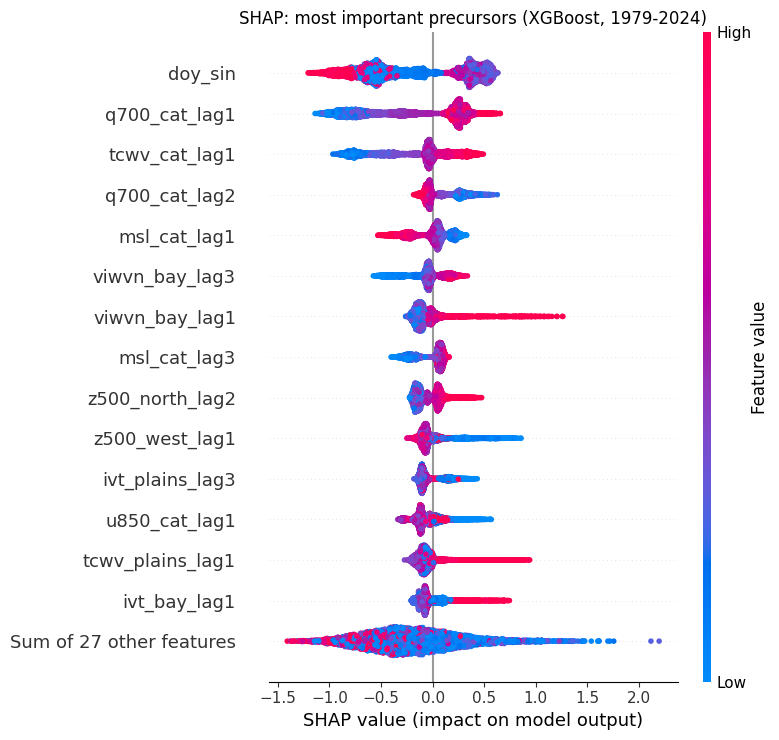

In [4]:
import shap
from xgboost import XGBClassifier
def xgb(): return XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7,
                                min_child_weight=5, reg_lambda=2.0, eval_metric='logloss', n_jobs=-1, random_state=0)
model = xgb().fit(table.loc[train, ATMOS], y[train])
explainer = shap.TreeExplainer(model)
sv = explainer(table.loc[train, ATMOS])
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP: most important precursors (XGBoost, 1979-2024)'); plt.tight_layout()
plt.savefig(f'{RES}/ml06_shap_beeswarm.png', dpi=150, bbox_inches='tight'); plt.show()

**How to read the beeswarm:** each dot is one day. Red = high value of that feature, blue = low.
Dots to the right push the probability of an extreme day **up**. For example, red dots on the right for `ivt_cat_lag1` mean "high moisture transport one day before raises the risk".

## Importance by variable and by lead time

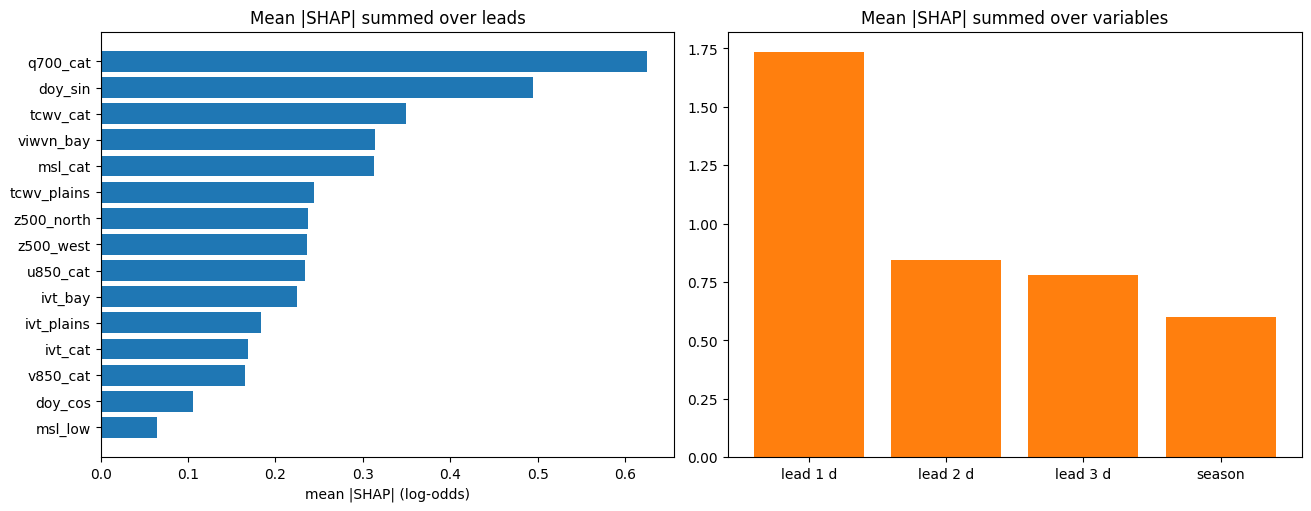

q700_cat       0.625
doy_sin        0.494
tcwv_cat       0.349
viwvn_bay      0.314
msl_cat        0.313
tcwv_plains    0.244
z500_north     0.237
z500_west      0.236
u850_cat       0.234
ivt_bay        0.225
ivt_plains     0.184
ivt_cat        0.169
v850_cat       0.165
doy_cos        0.105
msl_low        0.065


In [5]:
imp = pd.Series(np.abs(sv.values).mean(0), index=ATMOS)
by_var  = imp.groupby(lambda c_: c_.rsplit('_lag', 1)[0] if '_lag' in c_ else c_).sum().sort_values()
by_lead = imp.groupby(lambda c_: 'lead ' + c_.rsplit('_lag', 1)[1] + ' d' if '_lag' in c_ else 'season').sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
ax[0].barh(by_var.index, by_var.values); ax[0].set_title('Mean |SHAP| summed over leads'); ax[0].set_xlabel('mean |SHAP| (log-odds)')
ax[1].bar(by_lead.index, by_lead.values, color='tab:orange'); ax[1].set_title('Mean |SHAP| summed over variables')
plt.savefig(f'{RES}/ml06_importance_var_lead.png', dpi=150); plt.show()
print(by_var.sort_values(ascending=False).round(3).to_string())

## Why did the model react to E1 and E2? (peak rain day of each episode)

E1: peak rain-day 26 Aug (IMD date 27 Aug), rain 93 mm, forecast probability 0.29 (climatology 0.05)


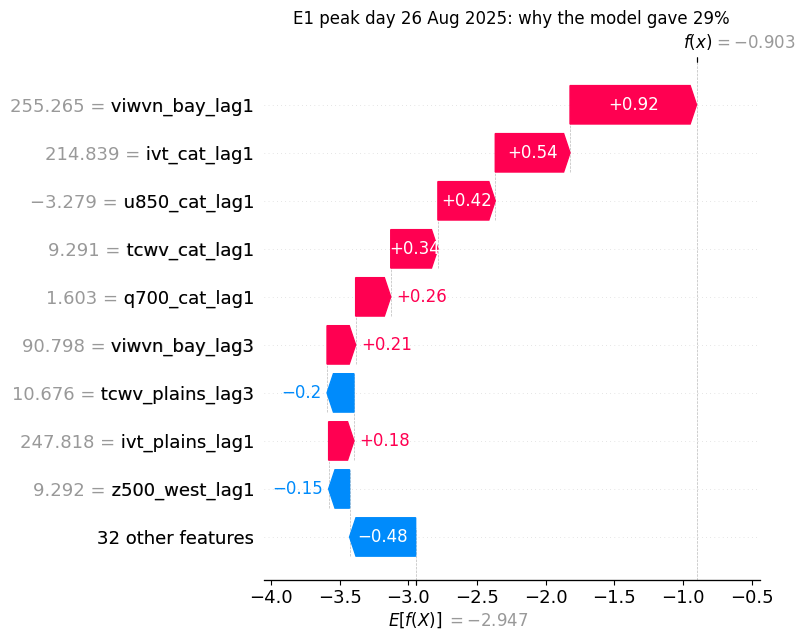

E2: peak rain-day 02 Sep (IMD date 03 Sep), rain 75 mm, forecast probability 0.34 (climatology 0.05)


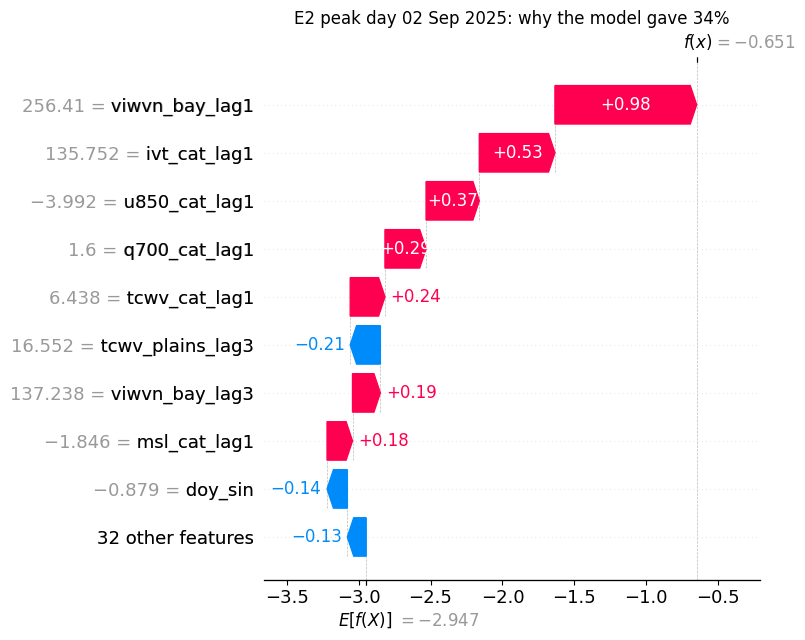

In [6]:
t25 = table[yr == 2025]
sv25 = explainer(t25[ATMOS])
p25 = pd.Series(model.predict_proba(t25[ATMOS])[:, 1], index=t25.index)
peaks = {}
for k, (a, b) in EPISODES.items():
    d = t25.loc[a:b, 'rain'].idxmax(); peaks[k] = d; i = t25.index.get_loc(d)
    print(f'{k}: peak rain-day {d:%d %b} (IMD date {d + pd.Timedelta(days=1):%d %b}), rain {t25.loc[d, "rain"]:.0f} mm, '
          f'forecast probability {p25[d]:.2f} (climatology {y[train].mean():.2f})')
    shap.plots.waterfall(sv25[i], max_display=10, show=False)
    plt.title(f'{k} peak day {d:%d %b %Y}: why the model gave {p25[d]:.0%}'); plt.tight_layout()
    plt.savefig(f'{RES}/ml06_waterfall_{k}.png', dpi=150, bbox_inches='tight'); plt.show()

## Summary numbers for your email (also saved as results/summary_for_email.txt)

In [7]:
s5 = pd.read_csv(f'{RES}/ml05_scores.csv', index_col=0) if os.path.exists(f'{RES}/ml05_scores.csv') else None
lines = [f'Target: extreme rain days (>= {PCT}th percentile of JJAS days) over the {TARGET} catchments, IMD 0.25 deg, 1979-2025.',
         f'Training/testing: 1979-2024 with 5-block year-wise cross-validation; 2025 kept as an independent test.',
         f'Predictors: {len(ATMOS)} ERA5 box-mean anomalies (IVT, TCWV, q700, 850 hPa winds, MSLP, Z500) at 1-3 day leads.']
if s5 is not None:
    for mname, r in s5.iterrows():
        lines.append(f'{mname}: ROC AUC {r.ROC_AUC}, PR AUC {r.PR_AUC} (base rate {r.base_rate}), BSS {r.BSS}, '
                     f'top-5% days hit rate {r.hit_rate_top5pct}')
lines.append('Top 5 precursors (mean |SHAP|): ' + ', '.join(by_var.sort_values(ascending=False).index[:5]))
lines.append('Importance by lead: ' + ', '.join(f'{k} {v:.2f}' for k, v in by_lead.items()))
for k, d in peaks.items():
    lines.append(f'2025 {k} peak day {d:%d %b}: forecast probability {p25[d]:.2f} vs climatology {y[train].mean():.2f}')
txt = '\n'.join(lines); print(txt)
open(f'{RES}/summary_for_email.txt', 'w').write(txt + '\n')

Target: extreme rain days (>= 95th percentile of JJAS days) over the ChenabRavi catchments, IMD 0.25 deg, 1979-2025.
Training/testing: 1979-2024 with 5-block year-wise cross-validation; 2025 kept as an independent test.
Predictors: 41 ERA5 box-mean anomalies (IVT, TCWV, q700, 850 hPa winds, MSLP, Z500) at 1-3 day leads.
Persistence (rain yesterday): ROC AUC 0.757, PR AUC 0.222 (base rate 0.05), BSS 0.07, top-5% days hit rate 0.288
LogReg leads 1-3 days: ROC AUC 0.81, PR AUC 0.196 (base rate 0.05), BSS 0.07, top-5% days hit rate 0.223
Random forest: ROC AUC 0.797, PR AUC 0.198 (base rate 0.05), BSS 0.076, top-5% days hit rate 0.241
XGBoost: ROC AUC 0.803, PR AUC 0.19 (base rate 0.05), BSS 0.069, top-5% days hit rate 0.237
Top 5 precursors (mean |SHAP|): q700_cat, doy_sin, tcwv_cat, viwvn_bay, msl_cat
Importance by lead: lead 1 d 1.73, lead 2 d 0.84, lead 3 d 0.78, season 0.60
2025 E1 peak day 26 Aug: forecast probability 0.29 vs climatology 0.05
2025 E2 peak day 02 Sep: forecast probabi

1030

## Think about it (this becomes your email)
1. Are the top precursors physically sensible? Which one surprised you?
2. Which lead time carries most information? What does that say about how early a warning could be given?
3. Send Claude the printed summary. Together we will turn it into 4-5 lines for Dr Vergopolan (Task 9).